# Data clustering K means
Chirag Rao KV

240962180

In [40]:
import numpy as np
from scipy.spatial.distance import euclidean
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram

In [41]:

X = np.array([
    [18, 3, 15],
    [19, 4, 14],
    [14, 5, 10],
    [14, 4, 8],
    [11, 7, 14],
    [20, 8, 13],
    [28, 7, 9],
    [30, 6, 5],
    [31, 9, 4],
    [35, 12, 11],
    [33, 14, 6],
    [25, 9, 5],
    [25, 4, 3],
    [27, 3, 8],
    [29, 4, 12],
    [30, 12, 7],
    [19, 15, 6],
    [23, 11, 5]
])
centroids = np.array([X[0], X[-1]], dtype=float)
cluster1 = []
cluster2 = []
print("Initial centroids:")
print("C1:", centroids[0])
print("C2:", centroids[1])
for i, player in enumerate(X):
    d1 = euclidean(player, centroids[0])
    d2 = euclidean(player, centroids[1])
    cluster = 1 if d1 < d2 else 2
    print(
        f"Player {i+1}: {player}, "
        f"d(C1) = {d1:.3f}, d(C2) = {d2:.3f}, "
        f"Cluster = {cluster}"
    )

    if cluster == 1:
        cluster1.append(player)
    else:
        cluster2.append(player)

new_c1 = np.mean(cluster1, axis=0)
new_c2 = np.mean(cluster2, axis=0)

print("\nNew centroids after one iteration:")
print("C1:", new_c1)
print("C2:", new_c2)


Initial centroids:
C1: [18.  3. 15.]
C2: [23. 11.  5.]
Player 1: [18  3 15], d(C1) = 0.000, d(C2) = 13.748, Cluster = 1
Player 2: [19  4 14], d(C1) = 1.732, d(C2) = 12.083, Cluster = 1
Player 3: [14  5 10], d(C1) = 6.708, d(C2) = 11.916, Cluster = 1
Player 4: [14  4  8], d(C1) = 8.124, d(C2) = 11.790, Cluster = 1
Player 5: [11  7 14], d(C1) = 8.124, d(C2) = 15.524, Cluster = 1
Player 6: [20  8 13], d(C1) = 5.745, d(C2) = 9.055, Cluster = 1
Player 7: [28  7  9], d(C1) = 12.329, d(C2) = 7.550, Cluster = 2
Player 8: [30  6  5], d(C1) = 15.906, d(C2) = 8.602, Cluster = 2
Player 9: [31  9  4], d(C1) = 18.055, d(C2) = 8.307, Cluster = 2
Player 10: [35 12 11], d(C1) = 19.647, d(C2) = 13.454, Cluster = 2
Player 11: [33 14  6], d(C1) = 20.664, d(C2) = 10.488, Cluster = 2
Player 12: [25  9  5], d(C1) = 13.601, d(C2) = 2.828, Cluster = 2
Player 13: [25  4  3], d(C1) = 13.928, d(C2) = 7.550, Cluster = 2
Player 14: [27  3  8], d(C1) = 11.402, d(C2) = 9.434, Cluster = 2
Player 15: [29  4 12], d(C1) 


EUCLIDEAN DISTANCE
K = 1, SSE = 1377.000
K = 2, SSE = 627.000
K = 3, SSE = 583.000
K = 4, SSE = 412.000


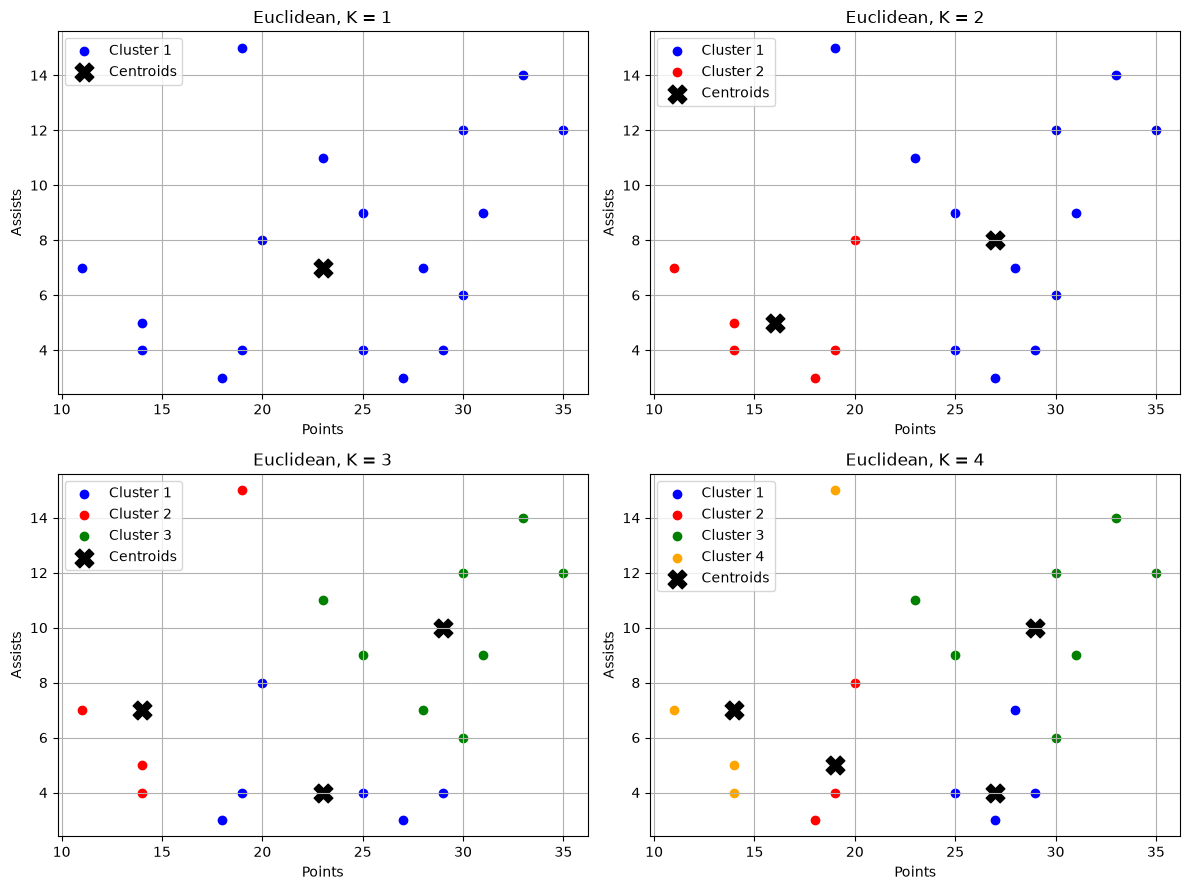

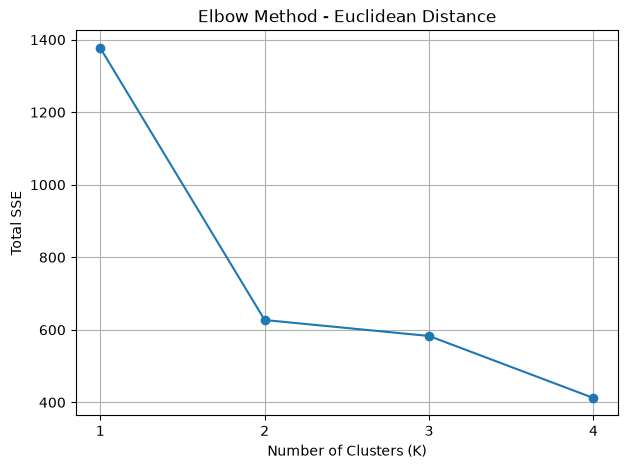


MANHATTAN DISTANCE
K = 1, SSE = 3053.000
K = 2, SSE = 1481.000
K = 3, SSE = 1058.000
K = 4, SSE = 980.000


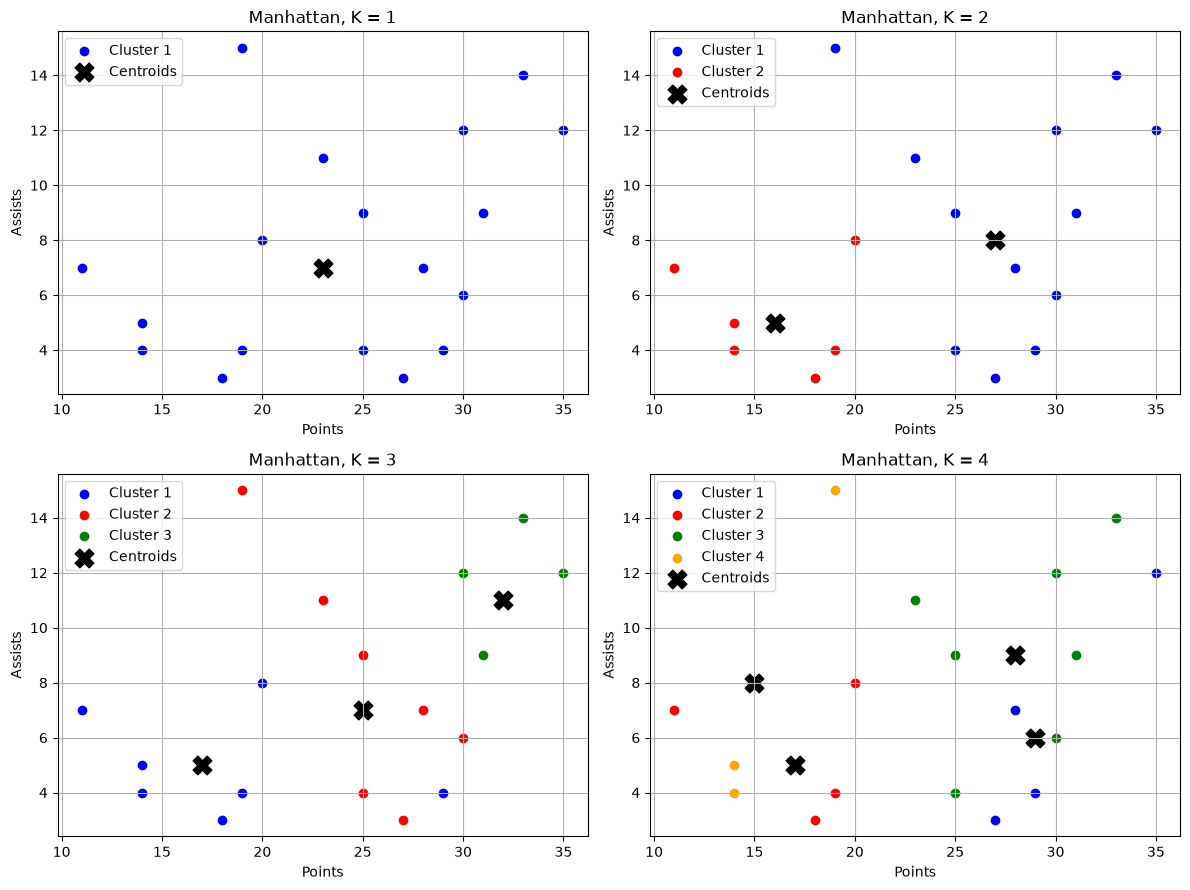

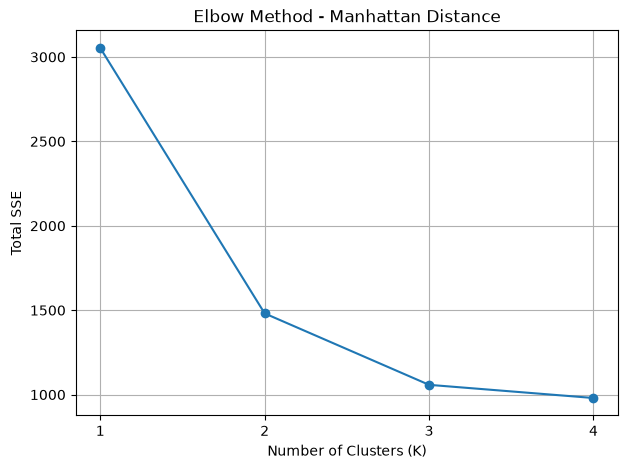


MINKOWSKI DISTANCE
K = 1, SSE = 1144.986
K = 2, SSE = 494.881
K = 3, SSE = 364.812
K = 4, SSE = 357.265


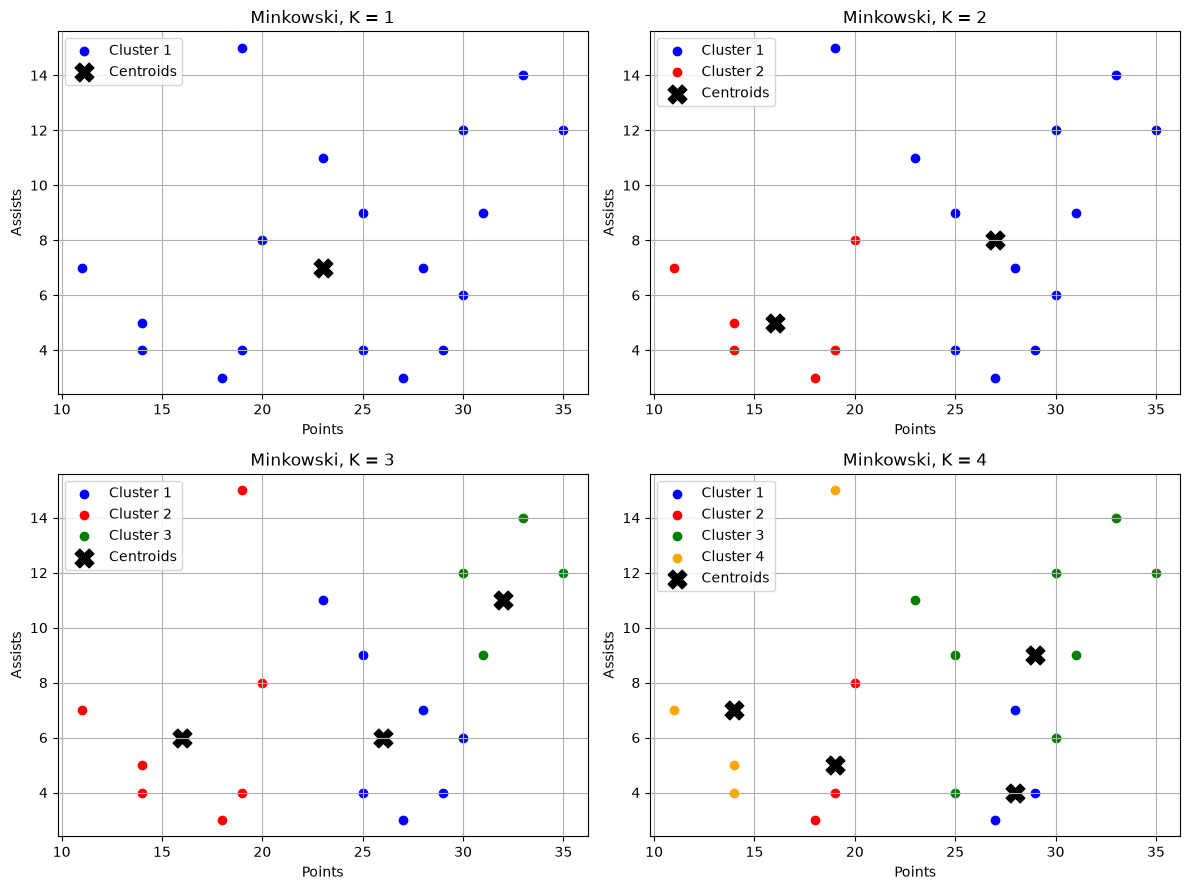

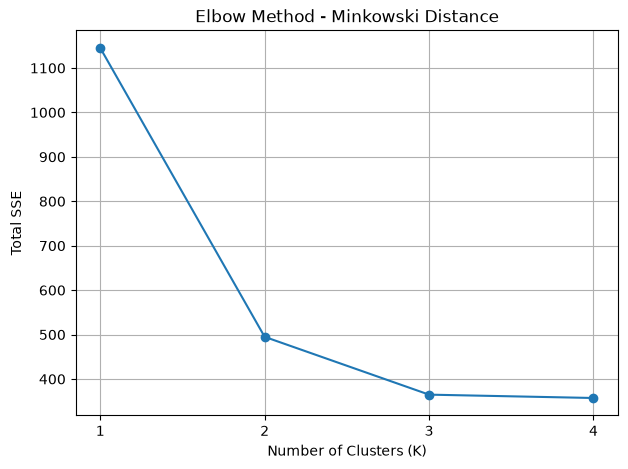

In [42]:
def distance(a, b, metric, p=3):
    if metric == "euclidean":
        return np.sqrt(np.sum((a - b) ** 2))
    elif metric == "manhattan":
        return np.sum(np.abs(a - b))
    elif metric == "minkowski":
        return np.sum(np.abs(a - b) ** p) ** (1 / p)

def kmeans(X, K, metric, max_iter=100):
    rng = np.random.default_rng(42 + K)
    centroids = X[rng.choice(len(X), K, replace=False)].copy()

    for _ in range(max_iter):
        distances = np.array([
            [distance(x, c, metric) for c in centroids]
            for x in X
        ])
        labels = np.argmin(distances, axis=1)
        new_centroids = centroids.copy()
        for j in range(K):
            if np.any(labels == j):
                new_centroids[j] = X[labels == j].mean(axis=0)
        if np.allclose(centroids, new_centroids):
            centroids = new_centroids
            break
        centroids = new_centroids

    # Calculate SSE using final centroids and assignments
    distances = np.array([
        [distance(x, c, metric) for c in centroids]
        for x in X
    ])
    labels = np.argmin(distances, axis=1)
    sse = np.sum(distances[np.arange(len(X)), labels] ** 2)

    return sse

K_values = [1, 2, 3, 4]
metrics = ["euclidean", "manhattan", "minkowski"]


colors = ["blue", "red", "green", "orange"]

for metric in metrics:
    sse_values = []

    fig, axes = plt.subplots(2, 2, figsize=(12, 9))
    axes = axes.flatten()

    print(f"\n{metric.upper()} DISTANCE")

    for idx, K in enumerate(K_values):
        # Run K-means
        sse = kmeans(X, K, metric)
        sse_values.append(sse)

        print(f"K = {K}, SSE = {sse:.3f}")

        # Recalculate labels and centroids for plotting
        rng = np.random.default_rng(42 + K)
        centroids = X[rng.choice(len(X), K, replace=False)].copy()

        for _ in range(100):
            distances = np.array([
                [distance(x, c, metric) for c in centroids]
                for x in X
            ])
            labels = np.argmin(distances, axis=1)

            new_centroids = centroids.copy()
            for j in range(K):
                if np.any(labels == j):
                    new_centroids[j] = X[labels == j].mean(axis=0)

            if np.allclose(centroids, new_centroids):
                centroids = new_centroids
                break

            centroids = new_centroids

        # Final assignments
        distances = np.array([
            [distance(x, c, metric) for c in centroids]
            for x in X
        ])
        labels = np.argmin(distances, axis=1)

        # Scatter plot: points vs assists
        ax = axes[idx]

        for j in range(K):
            cluster_points = X[labels == j]

            ax.scatter(
                cluster_points[:, 0],
                cluster_points[:, 1],
                color=colors[j],
                label=f"Cluster {j + 1}"
            )

        ax.scatter(
            centroids[:, 0],
            centroids[:, 1],
            color="black",
            marker="X",
            s=180,
            label="Centroids"
        )

        ax.set_title(f"{metric.title()}, K = {K}")
        ax.set_xlabel("Points")
        ax.set_ylabel("Assists")
        ax.legend()
        ax.grid(True)

    plt.tight_layout()
    plt.show()

    # Elbow graph
    plt.figure(figsize=(7, 5))
    plt.plot(K_values, sse_values, marker="o")
    plt.xticks(K_values)
    plt.xlabel("Number of Clusters (K)")
    plt.ylabel("Total SSE")
    plt.title(f"Elbow Method - {metric.title()} Distance")
    plt.grid(True)
    plt.show()


In [43]:


data = np.array([18, 22, 25, 27, 42, 43])
clusters = [[x] for x in data]

def distance(a, b):
    return min(abs(x - y) for x in a for y in b)

def print_matrix(clusters):
    n = len(clusters)
    matrix = np.zeros((n, n))

    for i in range(n):
        for j in range(i + 1, n):
            matrix[i, j] = matrix[j, i] = distance(
                clusters[i], clusters[j]
            )

    labels = [str(c[0]) if len(c) == 1 else str(c)
              for c in clusters]

    print("\nClusters:", labels)
    print(matrix)
    return matrix

# Initial proximity matrix
print("Initial proximity matrix:")
print_matrix(clusters)

linkage_matrix = []
next_id = len(data)

while len(clusters) > 1:
    matrix = print_matrix(clusters)

    # Find minimum non-zero distance
    i, j = np.unravel_index(
        np.where(matrix == np.min(
            matrix + np.eye(len(matrix)) * 1e9
        ), matrix, np.inf).argmin(),
        matrix.shape
    )

    # Merge closest clusters
    a, b = clusters[i], clusters[j]
    dist = distance(a, b)

    print(f"\nMerge {a} and {b}, distance = {dist}")

    # Record merge for dendrogram
    linkage_matrix.append([
        data.tolist().index(a[0]) if len(a) == 1 else next_id - 1,
        data.tolist().index(b[0]) if len(b) == 1 else next_id,
        dist,
        len(a) + len(b)
    ])

    merged = a + b
    clusters = [
        c for k, c in enumerate(clusters) if k not in (i, j)
    ]
    clusters.append(merged)
    next_id += 1

print("\nFinal cluster:", clusters[0])


Initial proximity matrix:

Clusters: ['18', '22', '25', '27', '42', '43']
[[ 0.  4.  7.  9. 24. 25.]
 [ 4.  0.  3.  5. 20. 21.]
 [ 7.  3.  0.  2. 17. 18.]
 [ 9.  5.  2.  0. 15. 16.]
 [24. 20. 17. 15.  0.  1.]
 [25. 21. 18. 16.  1.  0.]]

Clusters: ['18', '22', '25', '27', '42', '43']
[[ 0.  4.  7.  9. 24. 25.]
 [ 4.  0.  3.  5. 20. 21.]
 [ 7.  3.  0.  2. 17. 18.]
 [ 9.  5.  2.  0. 15. 16.]
 [24. 20. 17. 15.  0.  1.]
 [25. 21. 18. 16.  1.  0.]]

Merge [np.int64(42)] and [np.int64(43)], distance = 1

Clusters: ['18', '22', '25', '27', '[np.int64(42), np.int64(43)]']
[[ 0.  4.  7.  9. 24.]
 [ 4.  0.  3.  5. 20.]
 [ 7.  3.  0.  2. 17.]
 [ 9.  5.  2.  0. 15.]
 [24. 20. 17. 15.  0.]]

Merge [np.int64(25)] and [np.int64(27)], distance = 2

Clusters: ['18', '22', '[np.int64(42), np.int64(43)]', '[np.int64(25), np.int64(27)]']
[[ 0.  4. 24.  7.]
 [ 4.  0. 20.  3.]
 [24. 20.  0. 15.]
 [ 7.  3. 15.  0.]]

Merge [np.int64(22)] and [np.int64(25), np.int64(27)], distance = 3

Clusters: ['18', '[np.i

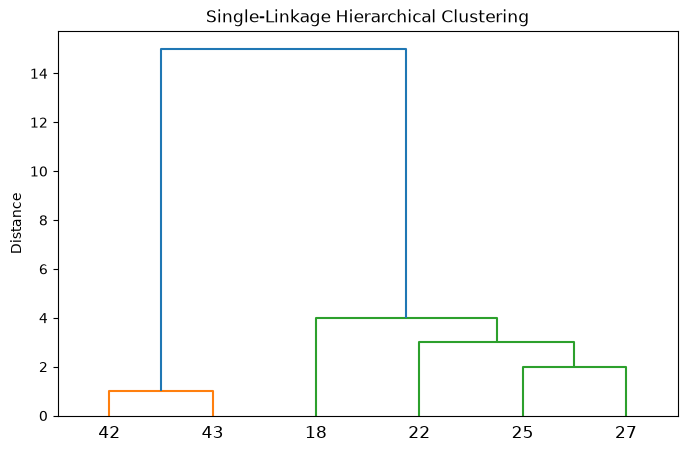

In [44]:
from scipy.cluster.hierarchy import linkage, dendrogram

Z = linkage(data.reshape(-1, 1), method="single")

plt.figure(figsize=(8, 5))
dendrogram(Z, labels=data.astype(str))
plt.ylabel("Distance")
plt.title("Single-Linkage Hierarchical Clustering")
plt.show()


SINGLE LINKAGE
Step 1: Merge D and H, Distance = 1.000
Step 2: Merge G and Cluster 1, Distance = 1.000
Step 3: Merge B and I, Distance = 1.414
Step 4: Merge A and Cluster 3, Distance = 2.000
Step 5: Merge C and E, Distance = 2.236
Step 6: Merge Cluster 4 and Cluster 5, Distance = 3.162
Step 7: Merge Cluster 2 and Cluster 6, Distance = 5.000
Step 8: Merge F and Cluster 7, Distance = 5.099

COMPLETE LINKAGE
Step 1: Merge D and H, Distance = 1.000
Step 2: Merge B and I, Distance = 1.414
Step 3: Merge G and Cluster 1, Distance = 1.414
Step 4: Merge C and E, Distance = 2.236
Step 5: Merge A and Cluster 2, Distance = 3.162
Step 6: Merge F and Cluster 4, Distance = 6.000
Step 7: Merge Cluster 3 and Cluster 5, Distance = 7.071
Step 8: Merge Cluster 6 and Cluster 7, Distance = 9.434

AVERAGE LINKAGE
Step 1: Merge D and H, Distance = 1.000
Step 2: Merge G and Cluster 1, Distance = 1.207
Step 3: Merge B and I, Distance = 1.414
Step 4: Merge C and E, Distance = 2.236
Step 5: Merge A and Cluster 3

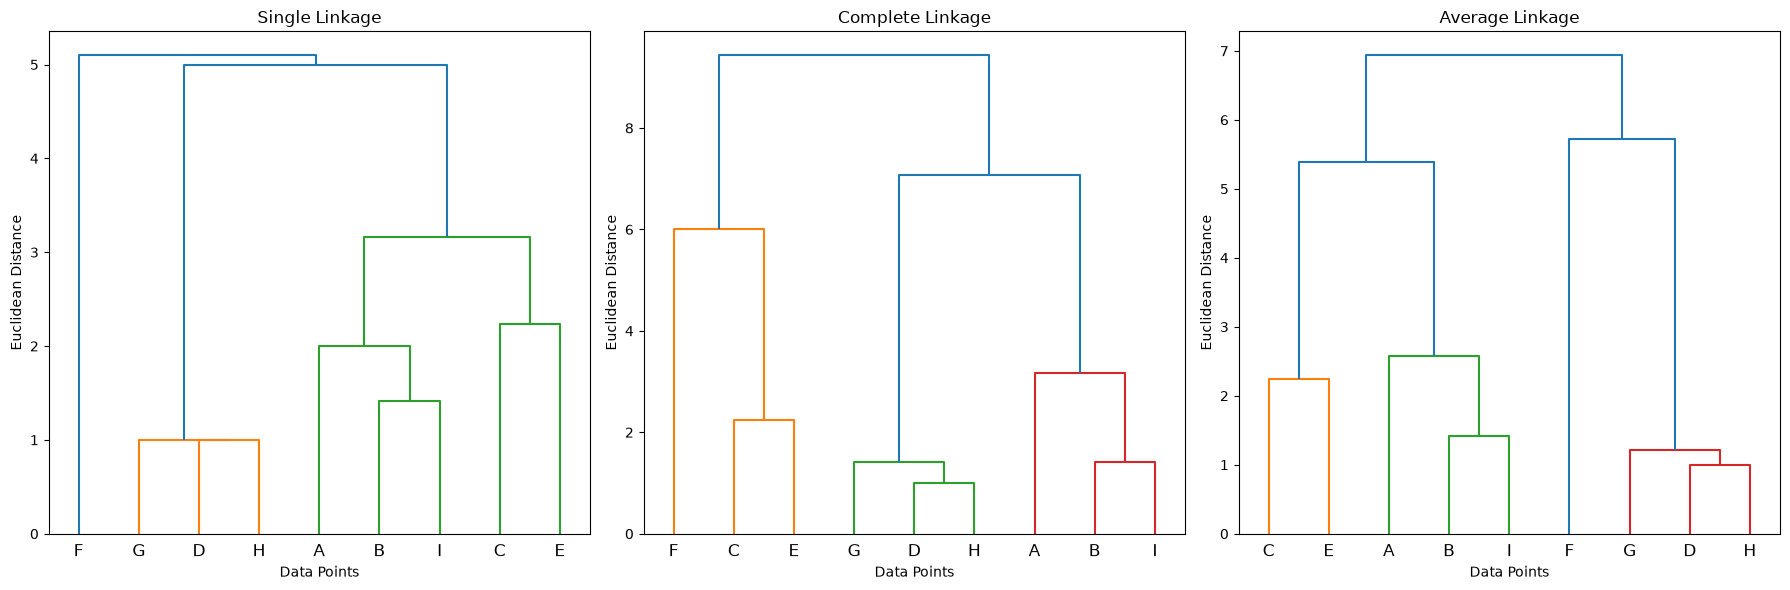

In [45]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram

# Given data points
points = np.array([
    [1, 2],
    [3, 2],
    [9, 1],
    [3, 7],
    [7, 2],
    [9, 7],
    [4, 8],
    [3, 8],
    [4, 1]
])
labels = ["A", "B", "C", "D", "E", "F", "G", "H", "I"]
methods = ["single", "complete", "average"]
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, method in zip(axes, methods):
    print(f"\n{method.upper()} LINKAGE")
    result = linkage(points, method=method, metric="euclidean")
    for step, row in enumerate(result, start=1):
        c1, c2, distance, size = row

        def cluster_name(index):
            if index < len(labels):
                return labels[int(index)]
            return f"Cluster {int(index) - len(labels) + 1}"
        print(
            f"Step {step}: Merge "
            f"{cluster_name(c1)} and {cluster_name(c2)}, "
            f"Distance = {distance:.3f}"
        )
    dendrogram(result, labels=labels, ax=ax)

    ax.set_title(f"{method.capitalize()} Linkage")
    ax.set_xlabel("Data Points")
    ax.set_ylabel("Euclidean Distance")

plt.tight_layout()
plt.show()


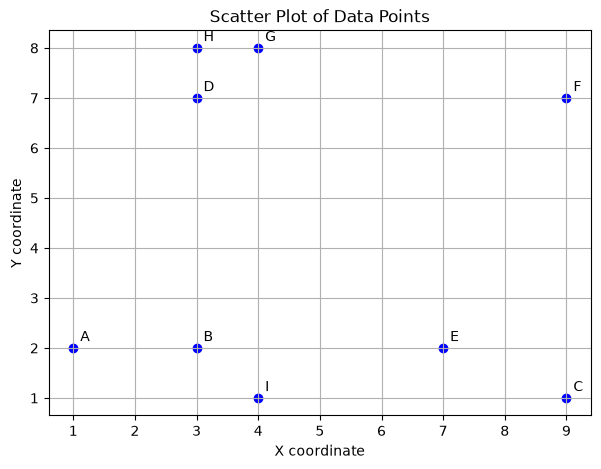


Euclidean Distance Matrix:
           A       B       C       D       E       F       G       H       I
  A     0.00    2.00    8.06    5.39    6.00    9.43    6.71    6.32    3.16
  B     2.00    0.00    6.08    5.00    4.00    7.81    6.08    6.00    1.41
  C     8.06    6.08    0.00    8.49    2.24    6.00    8.60    9.22    5.00
  D     5.39    5.00    8.49    0.00    6.40    6.00    1.41    1.00    6.08
  E     6.00    4.00    2.24    6.40    0.00    5.39    6.71    7.21    3.16
  F     9.43    7.81    6.00    6.00    5.39    0.00    5.10    6.08    7.81
  G     6.71    6.08    8.60    1.41    6.71    5.10    0.00    1.00    7.00
  H     6.32    6.00    9.22    1.00    7.21    6.08    1.00    0.00    7.07
  I     3.16    1.41    5.00    6.08    3.16    7.81    7.00    7.07    0.00

Manhattan Distance Matrix:
           A       B       C       D       E       F       G       H       I
  A     0.00    2.00    9.00    7.00    6.00   13.00    9.00    8.00    4.00
  B     2.00    0.00

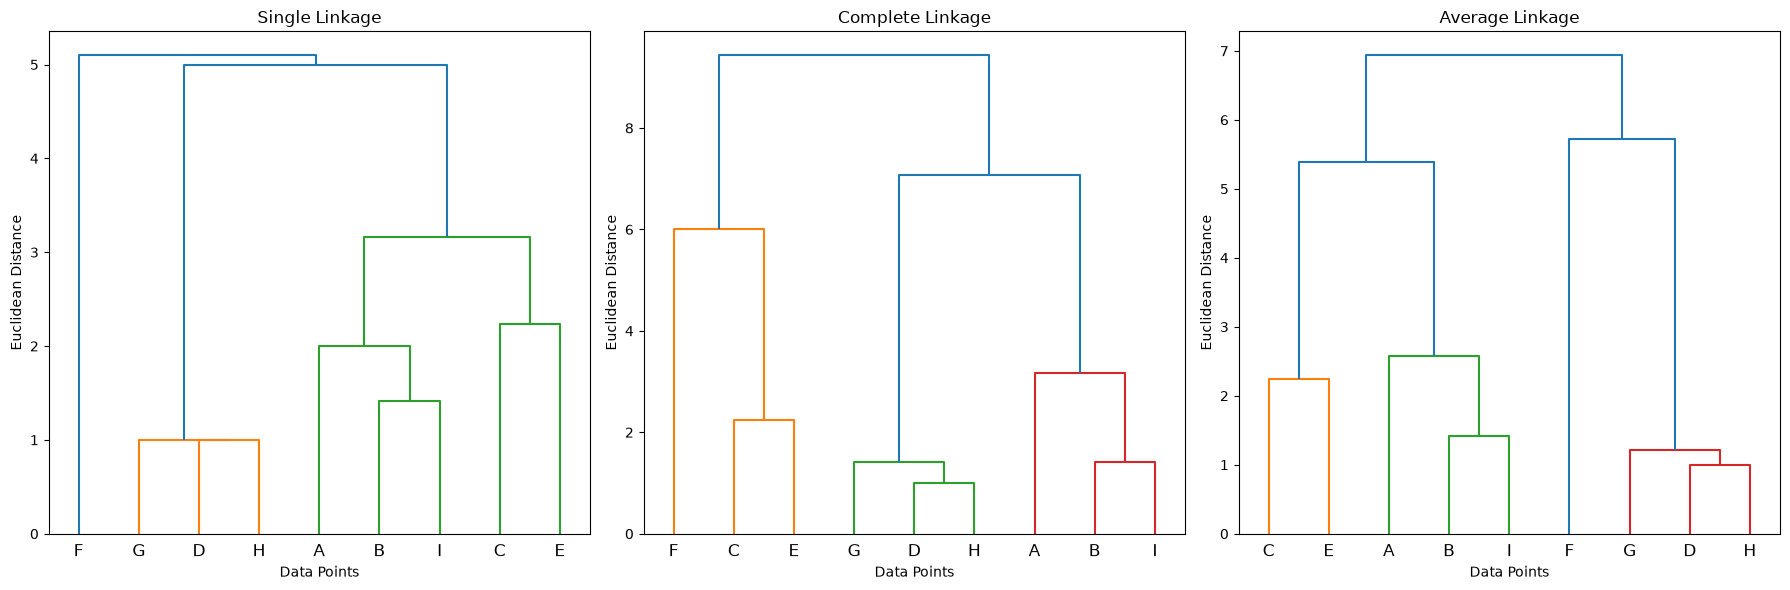

In [46]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist
from scipy.cluster.hierarchy import linkage, dendrogram
points = np.array([
    [1, 2],
    [3, 2],
    [9, 1],
    [3, 7],
    [7, 2],
    [9, 7],
    [4, 8],
    [3, 8],
    [4, 1]
])
labels = ["A", "B", "C", "D", "E", "F", "G", "H", "I"]

def plot_scatter(points, labels):
    plt.figure(figsize=(7, 5))

    plt.scatter(points[:, 0], points[:, 1], color="blue")

    for i, label in enumerate(labels):
        plt.annotate(label, points[i], xytext=(5, 5),
                     textcoords="offset points")
    plt.xlabel("X coordinate")
    plt.ylabel("Y coordinate")
    plt.title("Scatter Plot of Data Points")
    plt.grid(True)
    plt.show()


def proximity_matrices(points, labels):
    metrics = {
        "Euclidean": "euclidean",
        "Manhattan": "cityblock",
        "Minkowski (p=3)": "minkowski"
    }

    for name, metric in metrics.items():
        if metric == "minkowski":
            matrix = cdist(points, points, metric=metric, p=3)
        else:
            matrix = cdist(points, points, metric=metric)
        print(f"\n{name} Distance Matrix:")
        print("    ", " ".join(f"{label:>7}" for label in labels))

        for i, row in enumerate(matrix):
            print(f"{labels[i]:>3} ",
                  " ".join(f"{value:7.2f}" for value in row))


def plot_dendrograms(points, labels):
    methods = ["single", "complete", "average"]

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))

    for ax, method in zip(axes, methods):
        result = linkage(points, method=method, metric="euclidean")

        print(f"\n{method.upper()} LINKAGE:")
        for step, row in enumerate(result, start=1):
            c1, c2, distance, size = row

            def cluster_name(index):
                if index < len(labels):
                    return labels[int(index)]
                return f"Cluster {int(index) - len(labels) + 1}"

            print(
                f"Step {step}: Merge "
                f"{cluster_name(c1)} and {cluster_name(c2)}, "
                f"Distance = {distance:.3f}"
            )

        dendrogram(result, labels=labels, ax=ax)
        ax.set_title(f"{method.capitalize()} Linkage")
        ax.set_xlabel("Data Points")
        ax.set_ylabel("Euclidean Distance")

    plt.tight_layout()
    plt.show()

plot_scatter(points, labels)
proximity_matrices(points, labels)
plot_dendrograms(points, labels)
